
<div style="background-color:#174D32; padding:25px; border-radius:12px; color:white;">

<h1 style="color:white; text-align:center;">🌱 Smart Agriculture AI</h1>

<h3 style="color:#D7F5D0; text-align:center;">Machine Learning Based Crop Recommendation System</h3>

<p style="text-align:center;">
An intelligent agriculture project that analyzes soil nutrients and environmental conditions to recommend a suitable crop using Machine Learning.
</p>

<hr>

<p><b>Technologies:</b> Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn | Streamlit</p>

<p><b>Project Level:</b> Intermediate Data Science Project</p>

</div>



<div style="background-color:#E3F2FD; padding:18px; border-left:6px solid #1565C0; border-radius:8px;">

<h2 style="color:#1565C0;">📚 Step 1: Import Required Libraries</h2>

<p>In this step, we import the Python libraries required for data analysis, visualization, machine learning, and model saving.</p>

<ul>
<li><b>Pandas:</b> Loads and analyzes the dataset.</li>
<li><b>NumPy:</b> Supports numerical calculations.</li>
<li><b>Matplotlib and Seaborn:</b> Create charts and visualizations.</li>
<li><b>Scikit-learn:</b> Splits data, trains the model, and evaluates predictions.</li>
<li><b>Joblib:</b> Saves the trained model for future use.</li>
</ul>

</div>


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!



<div style="background-color:#E8F5E9; padding:18px; border-left:6px solid #2E7D32; border-radius:8px;">

<h2 style="color:#2E7D32;">📂 Step 2: Load the Crop Recommendation Dataset</h2>

<p>We load the <b>Crop_recommendation.csv</b> dataset using Pandas.</p>

<p>The dataset contains soil nutrient values, temperature, humidity, soil pH, rainfall, and the corresponding crop label.</p>

<p><b>Objective:</b> Understand the dataset structure and verify that the data has loaded correctly.</p>

</div>


In [6]:
df = pd.read_csv(r"C:\Users\SUMAN SETH\Downloads\Crop_recommendation.csv")
print("Dataset loaded successfully!")
print(df)

Dataset loaded successfully!
        N   P   K  temperature   humidity        ph    rainfall   label
0      90  42  43    20.879744  82.002744  6.502985  202.935536    rice
1      85  58  41    21.770462  80.319644  7.038096  226.655537    rice
2      60  55  44    23.004459  82.320763  7.840207  263.964248    rice
3      74  35  40    26.491096  80.158363  6.980401  242.864034    rice
4      78  42  42    20.130175  81.604873  7.628473  262.717340    rice
...   ...  ..  ..          ...        ...       ...         ...     ...
2195  107  34  32    26.774637  66.413269  6.780064  177.774507  coffee
2196   99  15  27    27.417112  56.636362  6.086922  127.924610  coffee
2197  118  33  30    24.131797  67.225123  6.362608  173.322839  coffee
2198  117  32  34    26.272418  52.127394  6.758793  127.175293  coffee
2199  104  18  30    23.603016  60.396475  6.779833  140.937041  coffee

[2200 rows x 8 columns]



<div style="background-color:#FFF3E0; padding:18px; border-left:6px solid #EF6C00; border-radius:8px;">

<h2 style="color:#E65100;">🔍 Step 3: Exploratory Data Analysis (EDA)</h2>

<p>Exploratory Data Analysis helps us understand the dataset before training a machine learning model.</p>

<ul>
<li>Display the first few records.</li>
<li>Check column names and data types.</li>
<li>Calculate statistical summaries.</li>
<li>Identify missing values and duplicate records.</li>
<li>Understand the distribution of crop categories.</li>
</ul>

<p><b>Objective:</b> Check data quality and discover patterns in agricultural data.</p>

</div>


In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (2200, 8)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [9]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [10]:
print("Total crops:", df["label"].nunique())
print("\nCrop names:")
print(sorted(df["label"].unique()))

Total crops: 22

Crop names:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']



<div style="background-color:#FCE4EC; padding:18px; border-left:6px solid #C2185B; border-radius:8px;">

<h2 style="color:#AD1457;">🧹 Step 4: Data Cleaning and Preprocessing</h2>

<p>Data cleaning improves data quality before model training.</p>

<ul>
<li>Check for missing values.</li>
<li>Identify duplicate records.</li>
<li>Remove duplicates if appropriate for the dataset.</li>
<li>Verify that the feature columns contain valid numerical values.</li>
</ul>

<p><b>Objective:</b> Prepare reliable input data for the machine learning workflow.</p>

</div>


In [11]:
print(df.isnull().sum())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
df = df.drop_duplicates().copy()
df = df.dropna().copy()
print("Dataset after cleaning:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset after cleaning: (2200, 8)
Missing values: 0
Duplicate rows: 0



<div style="background-color:#EDE7F6; padding:18px; border-left:6px solid #6A1B9A; border-radius:8px;">

<h2 style="color:#6A1B9A;">📊 Step 5: Agricultural Data Visualization</h2>

<p>Charts help us understand relationships between soil conditions, weather measurements, and crop categories.</p>

<ul>
<li>Crop distribution bar chart.</li>
<li>Nitrogen, phosphorus, and potassium comparison.</li>
<li>Temperature and rainfall analysis.</li>
<li>Correlation heatmap for numerical features.</li>
</ul>

<p><b>Objective:</b> Discover patterns that may help explain the model's crop predictions.</p>

</div>


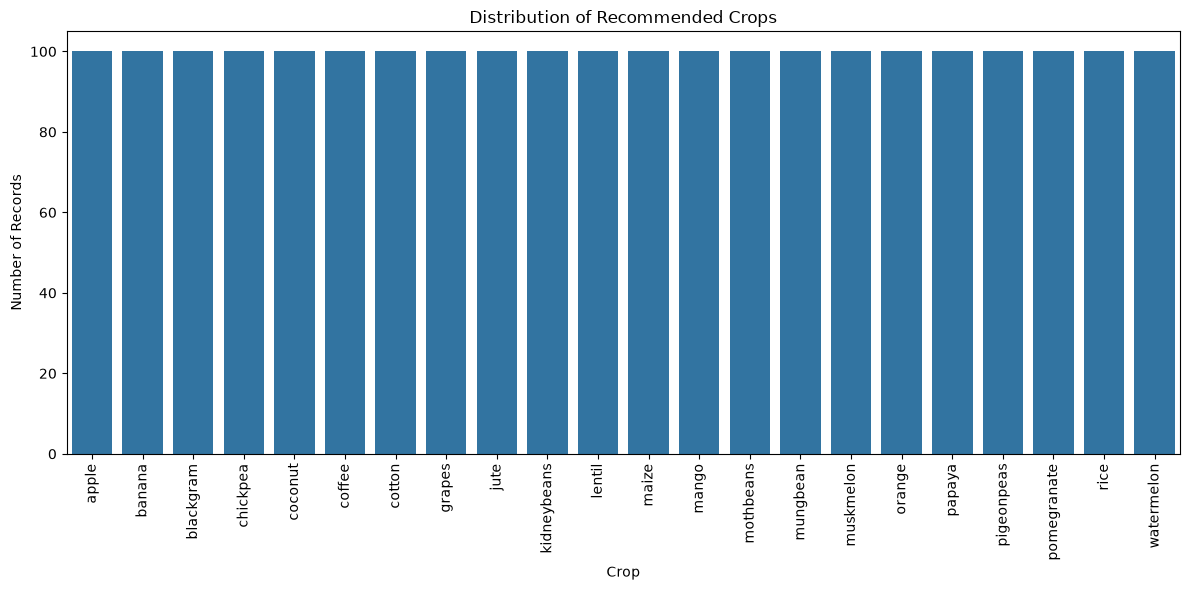

In [46]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="label", order=sorted(df["label"].unique()))
plt.title("Distribution of Recommended Crops")
plt.xlabel("Crop")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

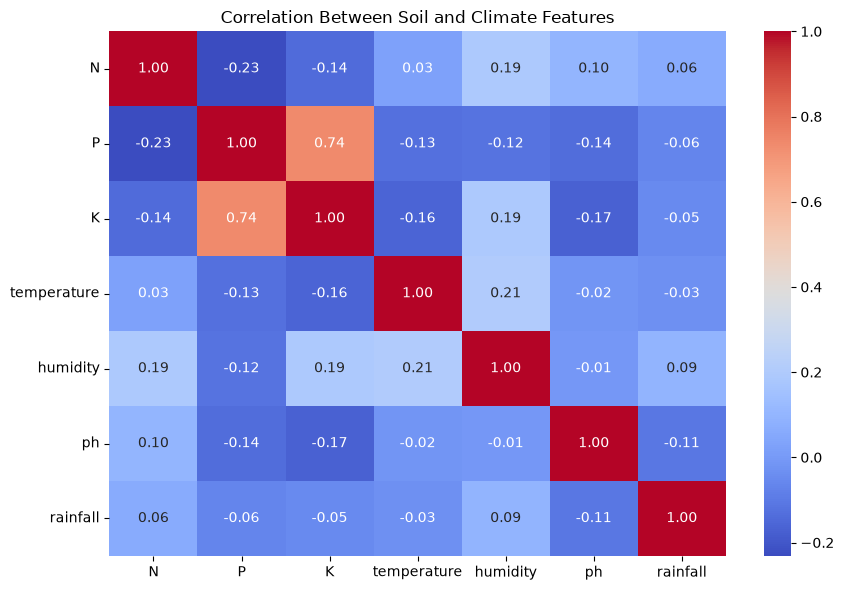

In [39]:
plt.figure(figsize=(9, 6))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Soil and Climate Features")
plt.tight_layout()
plt.show()


<div style="background-color:#E0F7FA; padding:18px; border-left:6px solid #00838F; border-radius:8px;">

<h2 style="color:#006064;">🎯 Step 6: Separate Features and Target</h2>

<p>Machine learning requires input features and a target variable.</p>

<ul>
<li><b>X:</b> Seven input features: N, P, K, temperature, humidity, pH, and rainfall.</li>
<li><b>y:</b> The target column, <code>label</code>, which contains the crop name.</li>
</ul>

<p><b>Objective:</b> Tell the model which agricultural measurements it should use to predict the crop category.</p>

</div>


In [40]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv(r"C:\Users\SUMAN SETH\Downloads\Crop_recommendation.csv")

# Input features (all columns except label)
X = df.drop("label", axis=1)

# Target variable (crop name)
y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2200, 7)
y shape: (2200,)



<div style="background-color:#E8EAF6; padding:18px; border-left:6px solid #3949AB; border-radius:8px;">

<h2 style="color:#283593;">✂️ Step 7: Split Training and Testing Data</h2>

<p>We divide the dataset into two parts so that we can train the model and evaluate it on records that were not used during training.</p>

<ul>
<li><b>80% training data:</b> Used to train the model.</li>
<li><b>20% testing data:</b> Used to evaluate the trained model.</li>
<li><b>Random state:</b> Keeps the split reproducible.</li>
<li><b>Stratification:</b> Helps preserve crop-class proportions in both sets.</li>
</ul>

<p><b>Objective:</b> Evaluate how well the model predicts crop labels on held-out data.</p>

</div>


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1760
Testing records: 440



<div style="background-color:#E0F2F1; padding:18px; border-left:6px solid #00796B; border-radius:8px;">

<h2 style="color:#00695C;">🤖 Step 8: Train the Random Forest Classifier</h2>

<p>Random Forest is a supervised machine learning algorithm that combines predictions from multiple decision trees.</p>

<ul>
<li>Learn patterns from the training data.</li>
<li>Use the seven agricultural features as inputs.</li>
<li>Predict the crop label.</li>
</ul>

<p><b>Objective:</b> Build a classification model that recommends a crop based on the input measurements.</p>

</div>


In [64]:
# Step 1: Import required libraries
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

# Step 2: Train the baseline model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
# Step 3: Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight=None,
    n_jobs=-1
)
# Step 4: Train the model
model.fit(X_train, y_train)

# Step 5: Display success message
print("Both models trained successfully!")

Both models trained successfully!


In [43]:
# Step 1: Import the required library
from sklearn.metrics import classification_report

# Step 2: Predict using the trained Random Forest model
y_pred = model.predict(X_test)

# Step 3: Display the classification report
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    


<div style="background-color:#F3E5F5; padding:18px; border-left:6px solid #8E24AA; border-radius:8px;">

<h2 style="color:#6A1B9A;">📈 Step 9: Model Evaluation</h2>

<p>We evaluate the trained model using the held-out test dataset.</p>

<ul>
<li><b>Accuracy:</b> Overall proportion of correct predictions.</li>
<li><b>Precision:</b> How many predictions for a crop were correct.</li>
<li><b>Recall:</b> How many actual records for a crop were correctly identified.</li>
<li><b>Macro F1-score:</b> Average F1-score across crop categories, giving each category equal weight.</li>
<li><b>Confusion matrix:</b> Shows correct and incorrect classifications by crop category.</li>
</ul>

<p><b>Objective:</b> Understand the model's strengths and classification errors.</p>

</div>


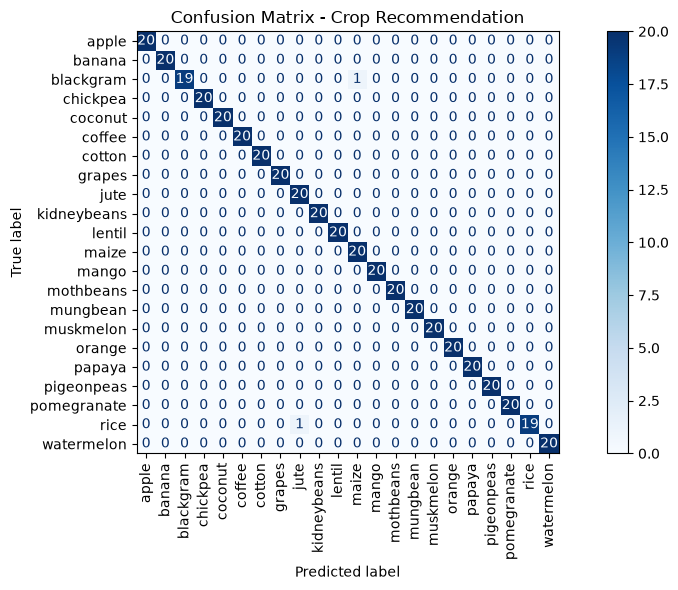

In [44]:
# Step 1: Import required libraries
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Step 2: Ensure predictions are available
y_pred = model.predict(X_test)

# Step 3: Create the confusion matrix
fig, ax = plt.subplots(figsize=(10,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax
)

plt.title("Confusion Matrix - Crop Recommendation")
plt.tight_layout()
plt.show()

       Feature  Importance
6     rainfall    0.219641
4     humidity    0.217058
2            K    0.180813
1            P    0.151342
0            N    0.103356
3  temperature    0.075485
5           ph    0.052305


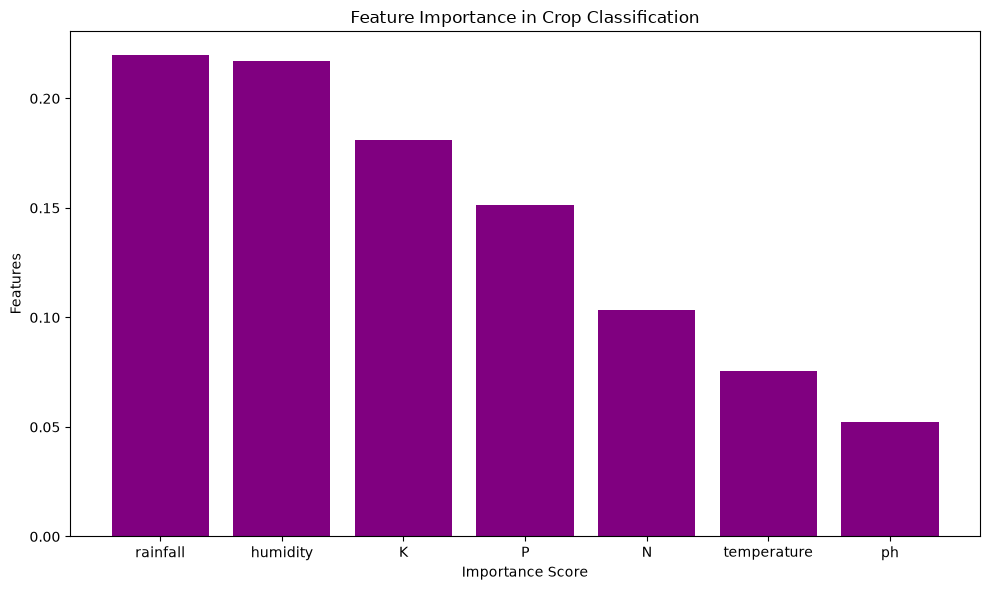

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Get feature names and importance values
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Step 2: Sort by importance
importance = importance.sort_values(
    "Importance",
    ascending=False
)

# Step 3: Display feature importance
print(importance)

# Step 4: Plot the chart
plt.figure(figsize=(10, 6))

plt.bar(
    importance["Feature"],
    importance["Importance"],
    color="Purple"
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance in Crop Classification")

#plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [47]:
sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.88,
    "humidity": 82.0,
    "ph": 6.5,
    "rainfall": 203.0
}])

predicted_crop = model.predict(sample)[0]

print("Recommended crop:", predicted_crop)

Recommended crop: rice


In [48]:
probabilities = model.predict_proba(sample)[0]

top_indices = np.argsort(probabilities)[::-1][:3]

for index in top_indices:
    print(
        f"{model.classes_[index]}: "
        f"{probabilities[index] * 100:.2f}%"
    )

rice: 93.50%
jute: 6.50%
pomegranate: 0.00%



<div style="background-color:#E8F5E9; padding:18px; border-left:6px solid #2E7D32; border-radius:8px;">

<h2 style="color:#2E7D32;">📊 Steps 10: Model Evaluation, Feature Importance & Saving</h2>

<p><b>Model Evaluation:</b> Evaluate the Random Forest model using accuracy, precision, recall, F1-score, and a confusion matrix.</p>

<p><b>Feature Importance:</b> Identify which soil and environmental features contribute most to the model's predictions.</p>

<p><b>Save the Model:</b> Save the trained model as <code>crop_model.pkl</code> using Joblib for use in the Streamlit dashboard.</p>

<p><b>Objective:</b> Evaluate model performance, understand its predictions, and prepare it for deployment.</p>

</div>


In [50]:
# Step 1: Import joblib
import joblib

# Step 2: Save the trained model
joblib.dump(model, "crop_model.pkl")

# Step 3: Confirm
print("Model saved as crop_model.pkl")

Model saved as crop_model.pkl


In [51]:
df.to_csv("Crop_recommendation.csv", index=False)

print("Clean dataset saved.")

Clean dataset saved.


In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict on test data
y_pred = model.predict(X_test)

# Calculate evaluation scores
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

# Display results
print("Random Forest Model Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")

Random Forest Model Performance
--------------------------------
Accuracy:  99.55%
Precision: 99.57%
Recall:    99.55%
F1 Score:  99.55%


In [54]:
from sklearn.metrics import accuracy_score

# Baseline model predictions
baseline_pred = baseline.predict(X_test)

# Random Forest predictions
rf_pred = model.predict(X_test)

print("Baseline Accuracy:",
      f"{accuracy_score(y_test, baseline_pred) * 100:.2f}%")

print("Random Forest Accuracy:",
      f"{accuracy_score(y_test, rf_pred) * 100:.2f}%")

Baseline Accuracy: 4.55%
Random Forest Accuracy: 99.55%



<div style="background-color:#174D32; padding:22px; border-radius:12px; color:white;">

<h2 style="color:white;">🌱 Step 11: Build the Interactive Streamlit Dashboard</h2>

<p>This step connects our trained machine learning model to an interactive web application.</p>

<ul>
<li><b>Crop Advisor:</b> Enter soil and weather conditions and get a prediction.</li>
<li><b>Soil Health:</b> Explore nutrient measurements and soil pH.</li>
<li><b>Data Analytics:</b> Filter crop records and explore interactive charts.</li>
<li><b>Model Insights:</b> Examine feature importance and dataset quality.</li>
<li><b>Download options:</b> Export filtered data and recommendation reports.</li>
</ul>

<p><b>Objective:</b> Turn the machine learning model into an application that users can interact with in a browser.</p>

</div>


In [1]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

# ---------------- PAGE CONFIG ----------------
st.set_page_config(
    page_title="AgriSmart AI | Smart Agriculture",
    page_icon="🌱",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ---------------- CUSTOM DESIGN ----------------
st.markdown("""
<style>
.stApp {
    background: linear-gradient(135deg, #f4f9f1, #edf5ed);
}
section[data-testid="stSidebar"] {
    background-color: #173d2b;
}
section[data-testid="stSidebar"] * {
    color: white !important;
}
.hero {
    padding: 28px;
    border-radius: 18px;
    background: linear-gradient(110deg, #174d32, #3b8050);
    color: white;
    margin-bottom: 20px;
}
.hero h1 { color: white; margin-bottom: 8px; }
.hero p { color: #e7f5e9; font-size: 17px; }
div[data-testid="stMetric"] {
    background: white;
    padding: 17px;
    border-radius: 14px;
    border: 1px solid #dce9dc;
}
.tip {
    background: white;
    padding: 16px;
    border-left: 5px solid #4a925d;
    border-radius: 9px;
    margin: 8px 0;
}
</style>
""", unsafe_allow_html=True)

# ---------------- LOAD PROJECT FILES ----------------
BASE_DIR = Path(__file__).resolve().parent

@st.cache_resource
def load_model():
    return joblib.load(BASE_DIR / "crop_model.pkl")

@st.cache_data
def load_data():
    return pd.read_csv(BASE_DIR / "Crop_recommendation.csv")

try:
    model = load_model()
    df = load_data()
except Exception as e:
    st.error(f"Could not load the project files: {e}")
    st.info(
        "Keep app.py, crop_model.pkl and Crop_recommendation.csv "
        "in the same folder."
    )
    st.stop()

required_columns = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall", "label"
]
missing = [c for c in required_columns if c not in df.columns]

if missing:
    st.error(f"Dataset is missing these columns: {missing}")
    st.stop()

FEATURES = required_columns[:-1]

if not hasattr(model, "predict"):
    st.error("The saved model does not support prediction.")
    st.stop()

# ---------------- SIDEBAR ----------------
st.sidebar.markdown("# 🌱 AgriSmart AI")
st.sidebar.caption("Smart Agriculture Intelligence")
st.sidebar.divider()

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "🏡 Home",
        "🌾 Crop Advisor",
        "🧪 Soil Health",
        "📊 Data Analytics",
        "🧠 Model Insights"
    ]
)

st.sidebar.divider()
st.sidebar.caption("Data-driven crop guidance")
st.sidebar.caption("Educational prototype")

# ---------------- HELPER FUNCTIONS ----------------
def make_input(n, p, k, temperature, humidity, ph, rainfall):
    return pd.DataFrame([{
        "N": n,
        "P": p,
        "K": k,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }], columns=FEATURES)

def predict_crop(input_df):
    # Use the exact feature names and order expected by the model.
    if hasattr(model, "feature_names_in_"):
        input_df = input_df[list(model.feature_names_in_)]
    return model.predict(input_df)[0]

def top_predictions(input_df):
    if not hasattr(model, "predict_proba"):
        return None

    if hasattr(model, "feature_names_in_"):
        input_df = input_df[list(model.feature_names_in_)]

    scores = model.predict_proba(input_df)[0]
    classes = model.classes_

    return pd.DataFrame({
        "Crop": classes,
        "Model score (%)": scores * 100
    }).sort_values("Model score (%)", ascending=False).head(3)

def hero(title, subtitle):
    st.markdown(
        f'<div class="hero"><h1>{title}</h1><p>{subtitle}</p></div>',
        unsafe_allow_html=True
    )

def crop_inputs():
    st.subheader("🌱 Enter your field conditions")
    st.caption("Enter measured values where possible. Example values are provided.")

    with st.form("crop_form"):
        c1, c2, c3 = st.columns(3)

        with c1:
            n = st.number_input("Nitrogen (N)", 0.0, 200.0, 90.0)
            p = st.number_input("Phosphorus (P)", 0.0, 200.0, 42.0)
            k = st.number_input("Potassium (K)", 0.0, 250.0, 43.0)

        with c2:
            temperature = st.number_input(
                "Temperature (°C)", -10.0, 60.0, 25.0
            )
            humidity = st.number_input(
                "Humidity (%)", 0.0, 100.0, 80.0
            )

        with c3:
            ph = st.number_input("Soil pH", 0.0, 14.0, 6.5)
            rainfall = st.number_input(
                "Rainfall (mm)", 0.0, 5000.0, 100.0
            )

        submitted = st.form_submit_button(
            "🌿 Recommend the Best-Matching Crop",
            type="primary",
            use_container_width=True
        )

    return submitted, make_input(
        n, p, k, temperature, humidity, ph, rainfall
    )

# ---------------- HOME ----------------
if page == "🏡 Home":
    hero(
        "🌱 AgriSmart AI",
        "Explore your agricultural data. Understand soil conditions. "
        "Discover a machine-learning-based crop recommendation."
    )

    st.subheader("Your Agriculture Dashboard")

    a, b, c, d = st.columns(4)
    a.metric("Dataset Records", f"{len(df):,}")
    b.metric("Crop Categories", df["label"].nunique())
    c.metric("Input Features", len(FEATURES))
    d.metric("Missing Values", int(df[required_columns].isna().sum().sum()))

    st.markdown("### Explore the platform")

    cards = st.columns(3)
    with cards[0]:
        st.markdown("#### 🌾 Crop Advisor")
        st.write("Enter seven soil and climate measurements to predict a crop.")
    with cards[1]:
        st.markdown("#### 🧪 Soil Health")
        st.write("Explore nutrient levels and understand soil measurements.")
    with cards[2]:
        st.markdown("#### 📊 Data Analytics")
        st.write("Investigate crop distribution and compare dataset patterns.")

    st.markdown("### Crop distribution in your dataset")
    crop_counts = df["label"].value_counts().rename_axis("Crop").reset_index(
        name="Records"
    )
    fig = px.bar(
        crop_counts,
        x="Crop",
        y="Records",
        color="Records",
        title="Number of records for each crop",
        color_continuous_scale="Greens"
    )
    fig.update_layout(xaxis_tickangle=-45)
    st.plotly_chart(fig, use_container_width=True)

    st.markdown(
        '<div class="tip"><b>Project goal:</b> use a trained machine '
        'learning model to identify the crop label that best matches '
        'the entered measurements in the training data.</div>',
        unsafe_allow_html=True
    )

# ---------------- CROP ADVISOR ----------------
elif page == "🌾 Crop Advisor":
    hero(
        "🌾 Smart Crop Advisor",
        "Enter field conditions and generate a model prediction."
    )

    submitted, input_df = crop_inputs()

    if submitted:
        try:
            prediction = predict_crop(input_df)

            st.divider()
            st.subheader("🌿 Recommendation Result")
            st.success(f"Model's recommended crop: **{str(prediction).title()}**")

            st.write("Your entered conditions")
            st.dataframe(input_df, use_container_width=True, hide_index=True)

            scores = top_predictions(input_df)

            if scores is not None:
                st.subheader("🏆 Top 3 model predictions")
                st.caption(
                    "These are model probability scores, not guaranteed "
                    "crop success rates or measured probabilities of "
                    "agricultural suitability."
                )

                fig = px.bar(
                    scores.sort_values("Model score (%)"),
                    x="Model score (%)",
                    y="Crop",
                    orientation="h",
                    text=scores.sort_values(
                        "Model score (%)"
                    )["Model score (%)"].map(lambda x: f"{x:.1f}%"),
                    title="Highest-scoring crop labels"
                )
                fig.update_layout(yaxis_title="", xaxis_range=[0, 100])
                st.plotly_chart(fig, use_container_width=True)

                st.download_button(
                    "⬇️ Download recommendation report",
                    data=(
                        "Smart Agriculture AI - Prediction Report\n\n"
                        f"Recommended crop: {prediction}\n\n"
                        + input_df.to_csv(index=False)
                        + "\nTop predictions:\n"
                        + scores.to_csv(index=False)
                    ),
                    file_name="crop_recommendation_report.txt",
                    mime="text/plain"
                )
            else:
                st.info(
                    "This saved model does not expose predict_proba, "
                    "so probability scores are unavailable."
                )

        except Exception as e:
            st.error(f"Prediction failed: {e}")
            st.info(
                "Check that the saved model was trained with the same "
                "seven input features and compatible column names."
            )

    st.info(
        "Tip: use actual soil-test and local weather measurements. "
        "The prediction is an educational model output, not professional "
        "agricultural advice."
    )

# ---------------- SOIL HEALTH ----------------
elif page == "🧪 Soil Health":
    hero(
        "🧪 Soil Health Explorer",
        "Explore nutrients, acidity, humidity, temperature and rainfall."
    )

    st.markdown("### Inspect a sample or enter your own values")

    mode = st.radio(
        "Choose data source",
        ["Enter field values", "Explore a dataset record"],
        horizontal=True
    )

    if mode == "Explore a dataset record":
        idx = st.slider("Select dataset row", 0, len(df) - 1, 0)
        selected = df.iloc[[idx]]
        st.write(f"Dataset crop label: **{selected.iloc[0]['label']}**")
        values = selected.iloc[0]
        vals = {feature: float(values[feature]) for feature in FEATURES}
    else:
        cols = st.columns(3)
        with cols[0]:
            vals = {"N": st.slider("Nitrogen (N)", 0, 200, 90)}
            vals["P"] = st.slider("Phosphorus (P)", 0, 200, 42)
            vals["K"] = st.slider("Potassium (K)", 0, 250, 43)
        with cols[1]:
            vals["temperature"] = st.slider(
                "Temperature (°C)", -10.0, 60.0, 25.0
            )
            vals["humidity"] = st.slider("Humidity (%)", 0.0, 100.0, 80.0)
        with cols[2]:
            vals["ph"] = st.slider("Soil pH", 0.0, 14.0, 6.5)
            vals["rainfall"] = st.slider(
                "Rainfall (mm)", 0.0, 5000.0, 100.0
            )

    nutrient_df = pd.DataFrame({
        "Nutrient": ["Nitrogen", "Phosphorus", "Potassium"],
        "Value": [vals["N"], vals["P"], vals["K"]]
    })

    left, right = st.columns(2)
    with left:
        fig = px.bar(
            nutrient_df,
            x="Nutrient",
            y="Value",
            color="Nutrient",
            title="NPK nutrient measurements"
        )
        st.plotly_chart(fig, use_container_width=True)

    with right:
        fig = go.Figure(go.Indicator(
            mode="gauge+number",
            value=vals["ph"],
            title={"text": "Soil pH"},
            gauge={
                "axis": {"range": [0, 14]},
                "steps": [
                    {"range": [0, 5.5], "color": "#f8d7da"},
                    {"range": [5.5, 7.5], "color": "#d4edda"},
                    {"range": [7.5, 14], "color": "#fff0c2"}
                ]
            }
        ))
        st.plotly_chart(fig, use_container_width=True)

    st.markdown("### Field measurements")
    metrics = st.columns(4)
    metrics[0].metric("Temperature", f"{vals['temperature']:.1f} °C")
    metrics[1].metric("Humidity", f"{vals['humidity']:.1f}%")
    metrics[2].metric("Rainfall", f"{vals['rainfall']:.1f} mm")
    metrics[3].metric("Soil pH", f"{vals['ph']:.2f}")

    st.caption(
        "The colors in the pH gauge are broad visual guides, not a "
        "crop-specific diagnosis. Interpret results using local soil "
        "testing guidance."
    )

# ---------------- DATA ANALYTICS ----------------
elif page == "📊 Data Analytics":
    hero(
        "📊 Agriculture Data Lab",
        "Filter the dataset, investigate patterns and export records."
    )

    search_crop = st.selectbox(
        "Filter by crop",
        ["All crops"] + sorted(df["label"].dropna().unique().tolist())
    )

    filtered = df.copy()
    if search_crop != "All crops":
        filtered = filtered[filtered["label"] == search_crop]

    min_n, max_n = float(df["N"].min()), float(df["N"].max())
    n_range = st.slider(
        "Nitrogen range",
        min_value=min_n,
        max_value=max_n,
        value=(min_n, max_n)
    )
    filtered = filtered[filtered["N"].between(*n_range)]

    x1, x2, x3 = st.columns(3)
    x1.metric("Filtered Records", f"{len(filtered):,}")
    x2.metric("Crop Types", filtered["label"].nunique())
    x3.metric(
        "Average Rainfall",
        f"{filtered['rainfall'].mean():.1f} mm"
        if not filtered.empty else "No data"
    )

    st.subheader("Feature relationship explorer")
    c1, c2 = st.columns(2)
    with c1:
        x_feature = st.selectbox("X-axis", FEATURES, index=0)
    with c2:
        y_feature = st.selectbox("Y-axis", FEATURES, index=3)

    if not filtered.empty:
        fig = px.scatter(
            filtered,
            x=x_feature,
            y=y_feature,
            color="label",
            hover_data=["label"],
            title=f"{x_feature} vs {y_feature} by crop"
        )
        st.plotly_chart(fig, use_container_width=True)
    else:
        st.warning("No records match these filters.")

    st.subheader("Feature correlation")
    numeric = df[FEATURES].select_dtypes(include=np.number)
    fig = px.imshow(
        numeric.corr(),
        text_auto=".2f",
        aspect="auto",
        color_continuous_scale="RdYlGn",
        title="Correlation between numerical features"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Filtered dataset")
    st.dataframe(filtered, use_container_width=True, hide_index=True)

    st.download_button(
        "⬇️ Download filtered CSV",
        data=filtered.to_csv(index=False),
        file_name="filtered_crop_data.csv",
        mime="text/csv"
    )

# ---------------- MODEL INSIGHTS ----------------
elif page == "🧠 Model Insights":
    hero(
        "🧠 Model Insights",
        "Explore what the trained model can tell you about its predictions."
    )

    st.subheader("Model information")

    info1, info2 = st.columns(2)
    info1.metric("Model type", type(model).__name__)
    info2.metric(
        "Classes known to model",
        len(getattr(model, "classes_", []))
    )

    if hasattr(model, "feature_names_in_"):
        model_features = list(model.feature_names_in_)
        st.write("Features expected by the saved model:")
        st.code(", ".join(model_features))
    else:
        st.info(
            "The model does not store feature names. Confirm its expected "
            "feature order from the training notebook."
        )

    if hasattr(model, "feature_importances_"):
        importances = pd.DataFrame({
            "Feature": FEATURES,
            "Importance": model.feature_importances_
        }).sort_values("Importance", ascending=False)

        st.subheader("Feature importance")
        fig = px.bar(
            importances.sort_values("Importance"),
            x="Importance",
            y="Feature",
            orientation="h",
            title="Which features influenced the trained forest?"
        )
        st.plotly_chart(fig, use_container_width=True)

        st.caption(
            "Feature importance measures the model's use of features. "
            "It does not establish that a feature causes crop growth."
        )
    else:
        st.info(
            "This model does not expose feature_importances_. "
            "If it is a pipeline, inspect its final estimator."
        )

    st.subheader("Dataset quality check")
    quality = pd.DataFrame({
        "Check": [
            "Rows",
            "Columns",
            "Missing cells",
            "Duplicate rows",
            "Number of crop labels"
        ],
        "Result": [
            len(df),
            len(df.columns),
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df["label"].nunique())
        ]
    })
    st.dataframe(quality, use_container_width=True, hide_index=True)

    st.subheader("Project workflow")
    st.markdown("""
    1. Load and inspect the crop dataset.
    2. Prepare input features and crop labels.
    3. Split data into training and testing sets.
    4. Train the Random Forest classifier.
    5. Evaluate performance on held-out test data.
    6. Save the model and load it into this dashboard.
    """)

# ---------------- FOOTER ----------------
st.divider()
st.caption(
    "AgriSmart AI • Student Data Science Project • "
    "Predictions are educational estimates, not farming guarantees."
)


Writing app.py


In [ ]:
!streamlit run app.py


<div style="background-color:#E3F2FD; padding:22px; border-radius:12px; border:1px solid #90CAF9;">

<h2 style="color:#1565C0;">🏆 Project Conclusion</h2>

<p>The Smart Agriculture AI project demonstrates how data analysis and supervised machine learning can be used to predict crop categories from soil nutrient values and environmental conditions.</p>

<p>The project combines data preprocessing, exploratory analysis, Random Forest classification, model evaluation, feature importance, and an interactive Streamlit dashboard.</p>

<p><b>Future Improvements:</b></p>

<ul>
<li>Use verified local agricultural data.</li>
<li>Include fertilizer recommendations based on agronomic guidance.</li>
<li>Incorporate local weather data.</li>
<li>Validate predictions with agricultural experts and field observations.</li>
</ul>

<p><b>Disclaimer:</b> This is an educational prototype. Predictions are not guarantees of crop suitability or yield.</p>

</div>
